# Figure 4 — HSP and Kunitz promoter/ATAC analysis (supplement)

Panels:
- **A.** Heat-shock protein genes: log2FC, average expression, ATAC-seq signal & HSF motif hits
- **C.** Kunitz-family genes (supplement): average expression (CPM) and log2FC heatmap per haplotype,
  plus promoter motif hits + ATAC-seq signal for a single Kunitz gene

The volcano plot and the enriched-motif / peptidase-allele panels for this dataset are
in `Fig3_heat_responsive_alleles_and_motifs.ipynb`.


In [1]:
library(dplyr)
library(tidyr)
library(stringr)
library(tibble)
library(readr)
library(ggplot2)
library(pheatmap)
library(RColorBrewer)
library(Biostrings)
library(rtracklayer)
library(patchwork)
library(ggseqlogo)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: S4Vectors

Loading required package: stats4


Attachi

## Setup

In [2]:
DATA_DIR <- "../clean_data/Fig4_HSP_Kunitz_supplement"
OUT_DIR  <- "./figures/Fig4"
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)

# --- pheatmap helper: display inline AND save a pdf copy with one call ---
make_pheatmap <- function(mat, filename, width, height, ...) {
  ph <- pheatmap(mat, ...)
  pheatmap(mat, ..., filename = filename, width = width, height = height)
  ph
}

# --- scan a set of sequences with one or more PWMs, both strands ---
# Always returns a properly-typed data frame, even with zero rows (i.e. no hits) --
# NULL$id <- ... silently turns a NULL into a plain list rather than a data frame,
# which then breaks any dplyr call (arrange/group_by/...) downstream.
EMPTY_MOTIF_HITS <- data.frame(id = character(0), pos = integer(0), strand = character(0),
                                motif = character(0), seq = character(0), score = numeric(0))

scan_pwm <- function(pwm, seqs, min.score = "90%", name = "motif") {
  rc <- reverseComplement(pwm)
  hits <- lapply(seq_along(seqs), function(i) {
    plus  <- matchPWM(pwm, seqs[[i]], min.score = min.score)
    minus <- matchPWM(rc,  seqs[[i]], min.score = min.score)
    rbind(
      if (length(plus))  data.frame(id = names(seqs)[i], pos = start(plus),  strand = "+", motif = name,
                                     seq = as.character(plus),
                                     score = 100 * PWMscoreStartingAt(pwm, seqs[[i]], start(plus)) / maxScore(pwm)),
      if (length(minus)) data.frame(id = names(seqs)[i], pos = start(minus), strand = "-", motif = name,
                                     seq = as.character(reverseComplement(DNAStringSet(minus))),
                                     score = 100 * PWMscoreStartingAt(rc, seqs[[i]], start(minus)) / maxScore(rc))
    )
  })
  hits <- hits[!vapply(hits, is.null, logical(1))]
  if (!length(hits)) return(EMPTY_MOTIF_HITS)
  do.call(rbind, hits)
}

# --- mean bigWig signal in `bin`-bp windows across a set of regions ---
extract_bw_signal <- function(bw_path, regions, bin = 25) {
  bwf <- BigWigFile(bw_path)
  nl  <- import(bwf, which = regions, as = "NumericList")

  neg <- as.character(strand(regions)) == "-"
  ids <- names(regions)

  do.call(rbind, lapply(seq_along(regions), function(i) {
    v <- as.numeric(nl[[i]])
    if (neg[i]) v <- rev(v)
    n    <- length(v)
    nb   <- ceiling(n / bin)
    idx  <- rep(seq_len(nb), each = bin, length.out = n)
    sig  <- tapply(v, idx, mean)
    data.frame(id = ids[i], pos = (seq_len(nb) - 0.5) * bin, signal = as.numeric(sig))
  }))
}

# --- resolve overlapping motif hits on the same sequence, keep the highest-scoring one per cluster ---
collapse_overlapping_hits <- function(df) {
  df %>%
    arrange(id, pos) %>%
    group_by(id) %>%
    group_modify(~{
      d <- .x[order(.x$pos), ]
      d$end <- d$pos + nchar(d$seq) - 1
      cl <- integer(nrow(d))
      if (nrow(d)) {
        cl[1] <- 1L; cur_end <- d$end[1]
        for (i in seq_len(nrow(d))[-1]) {
          if (d$pos[i] <= cur_end) {
            cl[i] <- cl[i - 1]; cur_end <- max(cur_end, d$end[i])
          } else {
            cl[i] <- cl[i - 1] + 1L; cur_end <- d$end[i]
          }
        }
      }
      d$cluster <- cl
      d
    }) %>%
    ungroup() %>%
    group_by(id, cluster) %>%
    slice_max(score, n = 1, with_ties = FALSE) %>%
    ungroup()
}

# --- shared promoter reference: 2000bp upstream + 500bp downstream of the TSS, per haplotype ---
# (already subset to just the Kunitz + heat-shock protein genes used in this notebook)
promoter_regions_all <- import(file.path(DATA_DIR, "kunitz_hsp_promoters_2000up_500down.gff3"))
promoter_regions_all <- promoter_regions_all[promoter_regions_all$type == "transcript"]
names(promoter_regions_all) <- promoter_regions_all$ID

promoter_seqs_all <- readDNAStringSet(file.path(DATA_DIR, "kunitz_hsp_promoters_2000up_500down.fa"))

ATAC_BIGWIG <- file.path(DATA_DIR, "kunitz_hsp_promoters_ATAC_HEAT.bigWig")


## Load DE results

`voom_results_desiree_liftoff_phased.tsv` is the batch-corrected, allele-level voom/limma
DE table (heat vs. control), already merged with average CPM per condition
(`avg_heat`, `avg_control`) and functional annotation (`functional_annotation`).

In [3]:
merged_data <- read_tsv(file.path(DATA_DIR, "voom_results_desiree_liftoff_phased.tsv"),
                         quote = "", show_col_types = FALSE)


## Panel A — Heat-shock protein genes: log2FC, average expression, ATAC-seq & motif hits

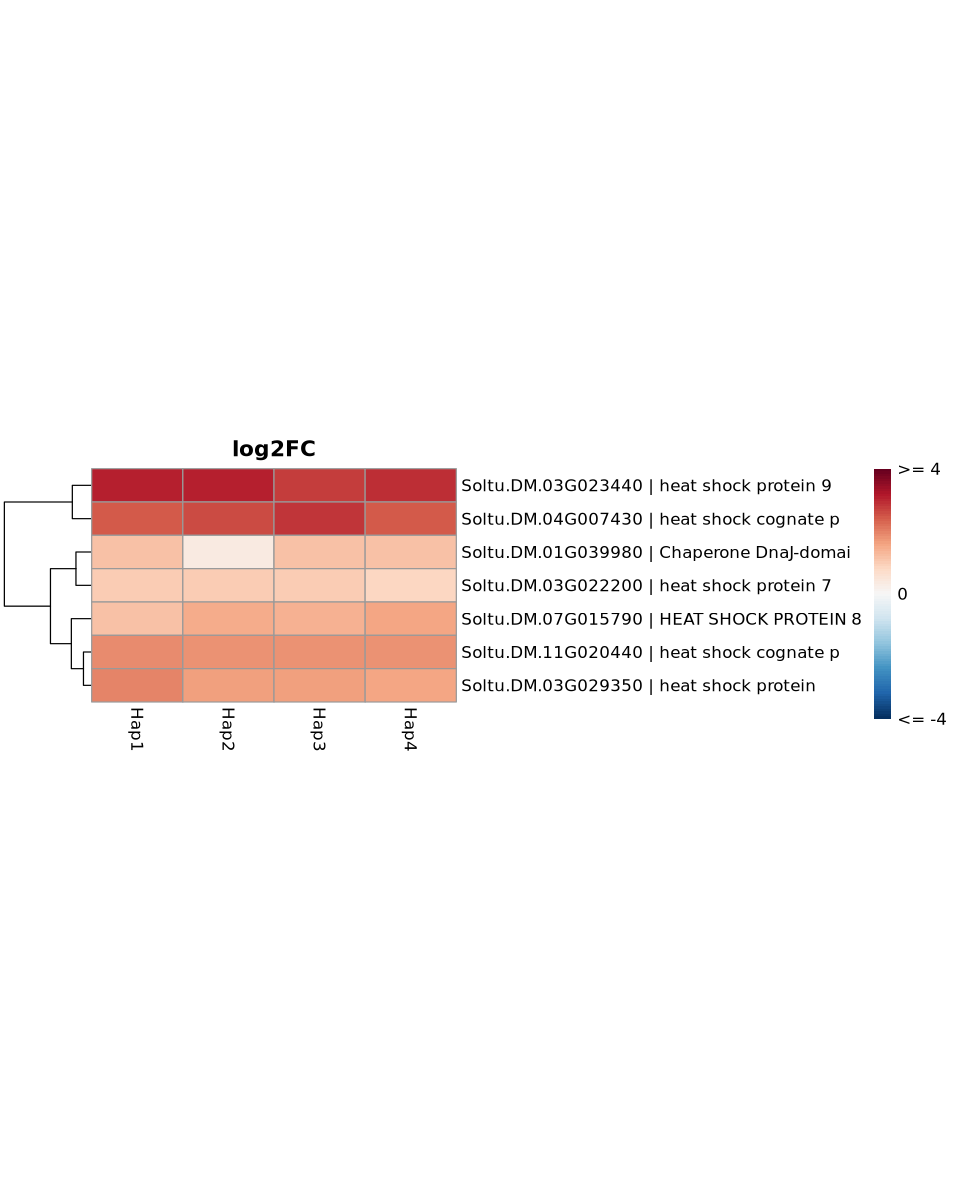

In [4]:
hsp_terms <- "heat shock protein|heat shock family|heat shock cognate|heat stress|chaperone|DnaJ|HSP|hsp"
hsp_gene_ids <- "SOLTU.DM.03G023440|SOLTU.DM.04G036710|SOLTU.DM.05G001570|SOLTU.DM.06G006550|SOLTU.DM.06G013460|SOLTU.DM.07G015790|SOLTU.DM.07G027620|SOLTU.DM.10G001010|SOLTU.DM.12G021000|SOLTU.DM.01G039370|SOLTU.DM.01G042380|SOLTU.DM.01G045550|SOLTU.DM.01G045580|SOLTU.DM.03G022200|SOLTU.DM.03G031850|SOLTU.DM.03G031860|SOLTU.DM.03G037330|SOLTU.DM.04G007430|SOLTU.DM.04G008820|SOLTU.DM.06G031410|SOLTU.DM.06G031840|SOLTU.DM.06G031850|SOLTU.DM.06G031870|SOLTU.DM.06G031880|SOLTU.DM.07G000910|SOLTU.DM.08G012580|SOLTU.DM.08G012670|SOLTU.DM.08G029760|SOLTU.DM.09G002330|SOLTU.DM.09G009430|SOLTU.DM.09G009450|SOLTU.DM.09G009460|SOLTU.DM.09G009470|SOLTU.DM.10G020640|SOLTU.DM.11G011960|SOLTU.DM.11G012220|SOLTU.DM.11G020400|SOLTU.DM.11G020440|SOLTU.DM.12G011130|SOLTU.DM.12G026330"

hsp_df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+")) %>%
  filter(str_detect(functional_annotation, regex(hsp_terms, ignore_case = TRUE)) |
         str_detect(gene_id_unitato, regex(hsp_gene_ids, ignore_case = TRUE))) %>%
  group_by(gene_id_unitato) %>%
  filter(any(logFC > 1)) %>%
  ungroup()

hsp_mat_logfc <- hsp_df %>%
  select(gene_id_unitato, haplotype, logFC) %>%
  pivot_wider(names_from = haplotype, values_from = logFC, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

hsp_mat_avg_heat <- hsp_df %>%
  select(gene_id_unitato, haplotype, avg_heat) %>%
  pivot_wider(names_from = haplotype, values_from = avg_heat, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

hsp_mat_avg_control <- hsp_df %>%
  select(gene_id_unitato, haplotype, avg_control) %>%
  pivot_wider(names_from = haplotype, values_from = avg_control, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

hsp_mat_complete <- hsp_mat_logfc[complete.cases(hsp_mat_logfc), ]

hsp_annot_map <- hsp_df %>%
  distinct(gene_id_unitato, functional_annotation) %>%
  mutate(short_annot = substr(functional_annotation, 1, 20))
hsp_row_labels <- paste0(rownames(hsp_mat_complete), " | ",
                         hsp_annot_map$short_annot[match(rownames(hsp_mat_complete), hsp_annot_map$gene_id_unitato)])

hsp_cap    <- 4
hsp_breaks <- seq(-hsp_cap, hsp_cap, length.out = 101)
hsp_mat_capped <- pmin(pmax(hsp_mat_complete, -hsp_cap), hsp_cap)
hsp_mat_capped <- hsp_mat_capped[, order(colnames(hsp_mat_capped))]

options(repr.plot.width = 8, repr.plot.height = 10)

# clusters genes by log2FC pattern; the row order (`ph$tree_row$order`) sets the gene
# order used by the combined plot below
ph <- pheatmap(hsp_mat_capped,
  labels_row = hsp_row_labels,
  cluster_cols = FALSE, cluster_rows = TRUE,
  color = colorRampPalette(rev(brewer.pal(11, "RdBu")))(100),
  breaks = hsp_breaks, na_col = "grey85",
  fontsize_row = 10, cellheight = 20,
  legend_breaks = c(-hsp_cap, 0, hsp_cap),
  legend_labels = c(paste0("<= -", hsp_cap), 0, paste0(">= ", hsp_cap)),
  main = "log2FC")


Warning message:
“The `<scale>` argument of `guides()` cannot be `FALSE`. Use "none" instead as
of ggplot2 3.3.4.
ℹ The deprecated feature was likely used in the ggseqlogo package.
  Please report the issue at <https://github.com/omarwagih/ggseqlogo/issues>.”


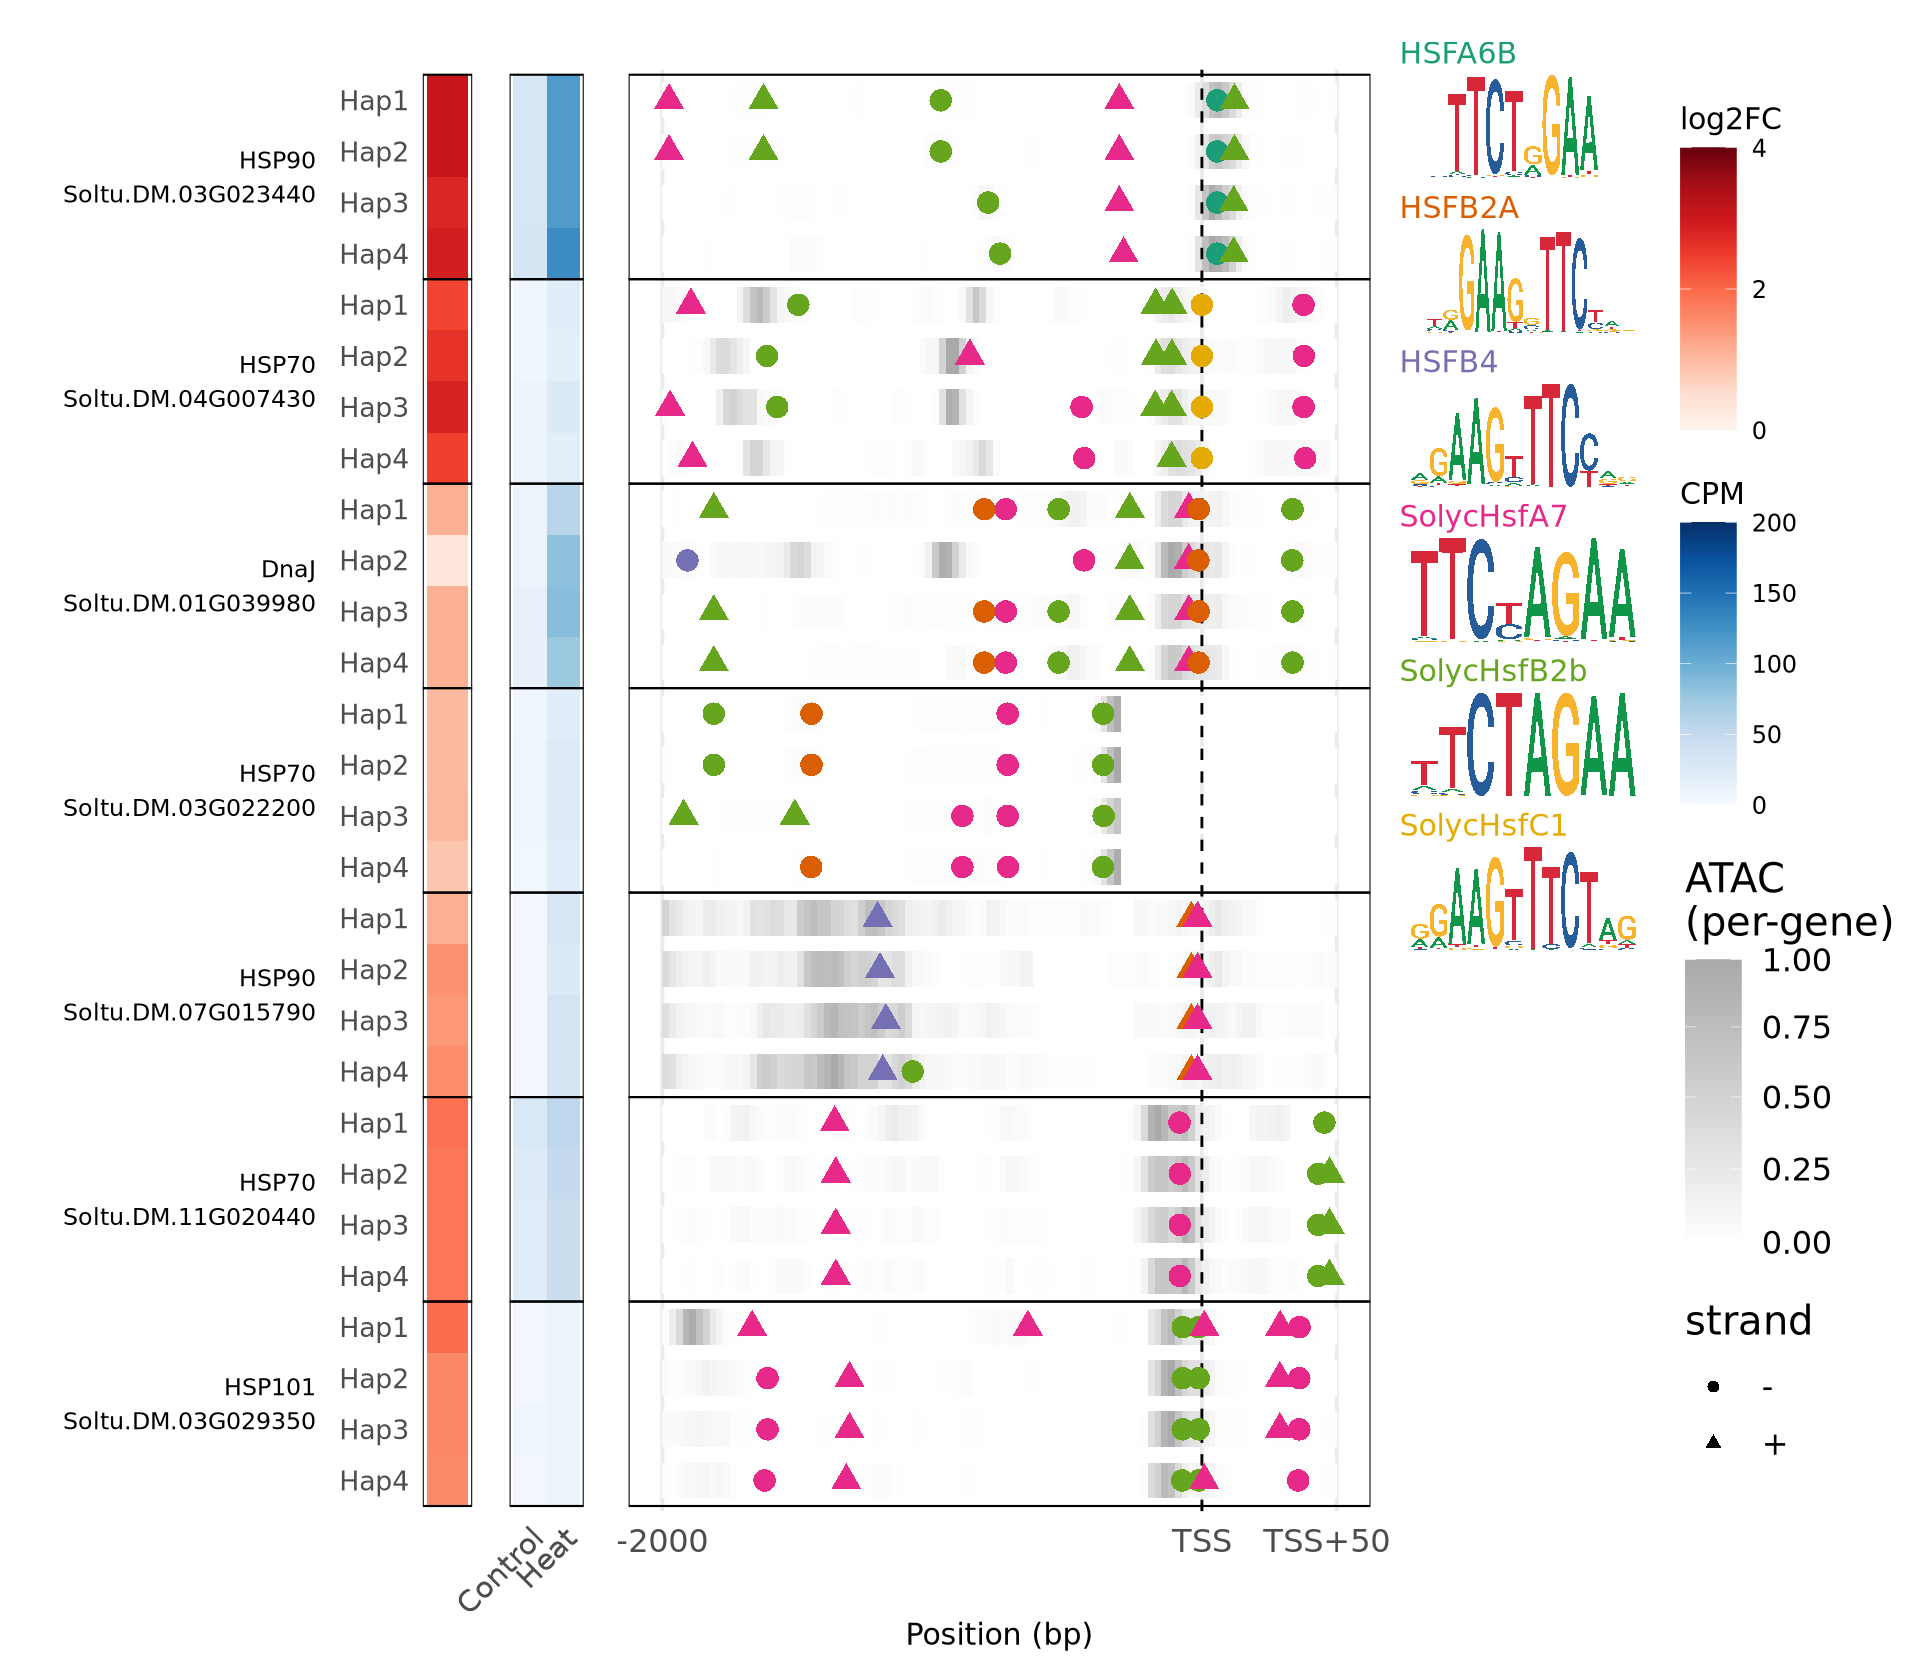

In [5]:
options(repr.plot.width = 16, repr.plot.height = 14)

# --- HSF-family PWMs (JASPAR) ---
SolycHsfA7_counts <- rbind(
  A = c(  74,   31,   16,  119, 2839,  113, 2915, 2818),
  C = c(  58,   18, 2909, 1169,   14,   49,   20,   17),
  G = c(  36,   15,   32,   64,   88, 2790,   10,   48),
  T = c(2809, 2913,   20, 1625,   36,   25,   32,   94)
)
storage.mode(SolycHsfA7_counts) <- "integer"

hsfa6b_counts <- rbind(
  A = c(205, 228,   47,   15,   13,   27, 366,   14, 1114, 1044, 268, 287),
  C = c(245, 412,   44,   18, 1108,   50,  78,   11,    7,   15, 259, 397),
  G = c(413, 234,   14,    9,   20,   16, 660, 1121,   12,   40, 364, 238),
  T = c(293, 282, 1051, 1114,   15, 1063,  52,   10,   23,   57, 265, 234)
)
storage.mode(hsfa6b_counts) <- "integer"

hsfb2a_counts <- rbind(
  A = c(206, 179, 374,   9, 878, 871,  46,  96,  22,  12,   7,  59, 431, 228),
  C = c(292, 171,  77,   4,   2,   1,  32, 264,   2,   2, 858, 261,  82, 131),
  G = c(154,  84, 390, 866,   2,   2, 713, 433,   4,   2,   7,  82, 181, 309),
  T = c(235, 453,  46,   8,   5,  13,  96,  94, 859, 871,  15, 485, 193, 219)
)
storage.mode(hsfb2a_counts) <- "integer"

hsfc1_counts <- rbind(
  A = c( 66,  52, 205, 205,   3,   7,   3,   4,   2,  11, 150,  26),
  C = c( 12,   6,   1,   2,   0,  18,   0,  14, 217,   7,  13,  17),
  G = c(126, 157,   7,   7, 213,  11,   0,   0,   1,   2,  29, 155),
  T = c( 18,   7,   9,   8,   6, 186, 219, 204,   2, 202,  30,  24)
)
storage.mode(hsfc1_counts) <- "integer"

hsfb4_counts <- rbind(
  A = c(44, 15, 81, 86,  2, 10,  2,  0,  0,  1, 42, 25),
  C = c(11,  4,  1,  1,  3, 16,  1,  0, 89, 62,  6,  8),
  G = c(25, 64,  4,  1, 83,  4,  0,  0,  0,  0, 30, 40),
  T = c( 9,  6,  3,  1,  1, 59, 86, 89,  0, 26, 11, 16)
)
storage.mode(hsfb4_counts) <- "integer"

hsfb2b_counts <- rbind(
  A = c( 705,  304,    0,    0, 5275,    0, 5239, 5273),
  C = c( 602,  195, 5275,    0,    1,    1,    2,    2),
  G = c( 255,   82,    1,    0,    0, 5274,    0,    0),
  T = c(3714, 4695,    0, 5276,    0,    1,   35,    1)
)
storage.mode(hsfb2b_counts) <- "integer"

pfm_list <- list(
  HSFA6B = hsfa6b_counts, HSFB2A = hsfb2a_counts, SolycHsfA7 = SolycHsfA7_counts,
  SolycHsfC1 = hsfc1_counts, HSFB4 = hsfb4_counts, SolycHsfB2b = hsfb2b_counts
)
hsp_pwms <- lapply(pfm_list, PWM)

# gene labels for the genes that made it into the final figure
hsp_gene_names <- c(
  "Soltu.DM.03G023440" = "HSP90",
  "Soltu.DM.03G022200" = "HSP70",
  "Soltu.DM.11G020440" = "HSP70",
  "Soltu.DM.04G007430" = "HSP70",
  "Soltu.DM.03G029350" = "HSP101",
  "Soltu.DM.07G015790" = "HSP90",
  "Soltu.DM.01G039980" = "DnaJ",
  "Soltu.DM.03G036440" = "HSP60"
)

hsp_wanted <- rownames(hsp_mat_capped)
# match on "<gene_id>." (with the trailing dot) so a gene id that happens to be a
# string-prefix of another can't accidentally swallow the other gene's sequences
hsp_idx    <- unlist(lapply(hsp_wanted, function(g) which(startsWith(names(promoter_seqs_all), paste0(g, ".")))))
hsp_seqs   <- promoter_seqs_all[hsp_idx]

hsp_motifs <- do.call(rbind, Map(function(p, n) scan_pwm(p, hsp_seqs, name = n), hsp_pwms, names(hsp_pwms)))

# gene order = the hierarchical-clustering order from the log2FC heatmap above
hsp_ordered_ids <- rownames(hsp_mat_capped)[ph$tree_row$order]
hsp_id_order <- unlist(lapply(hsp_ordered_ids,
                              function(g) names(hsp_seqs)[startsWith(names(hsp_seqs), paste0(g, "."))]))
hsp_motifs$id <- factor(hsp_motifs$id, levels = rev(hsp_id_order))

hsp_gene_of <- vapply(names(hsp_seqs), function(x) {
  i <- which(startsWith(x, paste0(hsp_ordered_ids, "."))); if (length(i)) hsp_ordered_ids[i[1]] else NA_character_
}, character(1))
hsp_hap_of <- str_extract(names(hsp_seqs), "Hap\\d+")
names(hsp_hap_of) <- names(hsp_seqs)

# axis tick labels are just the haplotype (Hap1..Hap4) for every row now -- the
# gene name/id is drawn separately below, centered on the gene's whole haplotype
# block, instead of being glued onto the Hap1 row's tick label
hsp_id_labels <- hsp_hap_of[names(hsp_seqs)]
names(hsp_id_labels) <- names(hsp_seqs)

hsp_regions <- promoter_regions_all[names(promoter_regions_all) %in% hsp_id_order]

# Soltu.DM.03G022200's TSS annotation is offset by 800bp; correct it before extracting signal
idx_shift <- startsWith(names(hsp_regions), "Soltu.DM.03G022200")
ranges(hsp_regions)[idx_shift] <- IRanges(start = start(hsp_regions)[idx_shift] + 800,
                                          end = end(hsp_regions)[idx_shift] + 800)

hsp_atac <- extract_bw_signal(ATAC_BIGWIG, hsp_regions, bin = 25)
hsp_atac <- hsp_atac %>%
  mutate(gene = hsp_gene_of[as.character(id)]) %>%
  group_by(gene) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
hsp_atac$id <- factor(hsp_atac$id, levels = rev(hsp_id_order))

# per-(gene x haplotype) log2FC / average-expression tables matching the FASTA ids
hsp_fc_long <- data.frame(
  id   = names(hsp_seqs),
  gene = hsp_gene_of[names(hsp_seqs)],
  hap  = hsp_hap_of[names(hsp_seqs)],
  stringsAsFactors = FALSE
)
hsp_fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(hsp_mat_complete) && h %in% colnames(hsp_mat_complete))
    hsp_mat_complete[g, h] else NA_real_
}, hsp_fc_long$gene, hsp_fc_long$hap)
hsp_fc_long$logFC_capped <- pmin(pmax(hsp_fc_long$logFC, -hsp_cap), hsp_cap)

hsp_fc_long$avgHeat <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(hsp_mat_avg_heat) && h %in% colnames(hsp_mat_avg_heat))
    hsp_mat_avg_heat[g, h] else NA_real_
}, hsp_fc_long$gene, hsp_fc_long$hap)
hsp_fc_long$avgControl <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(hsp_mat_avg_control) && h %in% colnames(hsp_mat_avg_control))
    hsp_mat_avg_control[g, h] else NA_real_
}, hsp_fc_long$gene, hsp_fc_long$hap)

hsp_avg_long <- hsp_fc_long %>%
  select(id, avgControl, avgHeat) %>%
  pivot_longer(cols = c(avgControl, avgHeat), names_to = "condition", values_to = "avgExpr")
hsp_avg_long$condition <- factor(hsp_avg_long$condition,
                                 levels = c("avgControl", "avgHeat"), labels = c("Control", "Heat"))
hsp_fc_long$id <- factor(hsp_fc_long$id, levels = rev(hsp_id_order))

hsp_box_df <- data.frame(id = levels(hsp_fc_long$id),
                         ypos = seq_along(levels(hsp_fc_long$id)),
                         stringsAsFactors = FALSE)
hsp_box_df$gene <- hsp_gene_of[hsp_box_df$id]
hsp_box_df <- hsp_box_df %>%
  group_by(gene) %>%
  summarise(ymin = min(ypos) - 0.5, ymax = max(ypos) + 0.5, .groups = "drop")
# gene name/id label text, one per gene, positioned at the vertical center of its
# haplotype block (used by the standalone label panel below)
hsp_box_df$label <- paste0(hsp_gene_names[hsp_box_df$gene], "\n", hsp_box_df$gene)

hsp_motifs <- collapse_overlapping_hits(hsp_motifs)
# after the 800bp TSS correction, drop any motif that now falls outside the promoter window
hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap1"] <- hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap1"] - 800
hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap2"] <- hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap2"] - 800
hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap3"] <- hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap3"] - 800
hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap4"] <- hsp_motifs$pos[hsp_motifs$id == "Soltu.DM.03G022200.Hap4"] - 800
hsp_motifs <- hsp_motifs[hsp_motifs$pos >= 0 & hsp_motifs$pos <= 2500, ]

hsp_motif_levels <- sort(unique(hsp_motifs$motif))
hsp_motif_cols   <- setNames(brewer.pal(length(hsp_motif_levels), "Dark2"), hsp_motif_levels)

hsp_logo_plots <- lapply(hsp_motif_levels, function(m) {
  ggseqlogo(pfm_list[[m]]) +
    ggtitle(m) +
    theme_void(base_size = 15) +
    theme(plot.title = element_text(colour = hsp_motif_cols[m], hjust = 0))
})
p_hsp_legend <- wrap_plots(
  c(hsp_logo_plots, list(plot_spacer())),
  ncol = 1,
  heights = c(rep(1, length(hsp_logo_plots)), length(hsp_logo_plots) * 0.8)
)

# standalone panel just for gene name/id labels, one per gene, vertically centered
# on that gene's Hap1-Hap4 block (same y-position scale as the id/box rows in the
# heatmap panels, so it lines up with them when combined via patchwork)
p_hsp_labels <- ggplot(hsp_box_df, aes(x = 1, y = (ymin + ymax) / 2, label = label)) +
  geom_text(hjust = 1, size = 5) +
  scale_y_continuous(limits = c(0.4, length(hsp_id_order) + 0.6), expand = c(0, 0)) +
  scale_x_continuous(limits = c(0, 1)) +
  labs(x = NULL, y = NULL) +
  theme_void(base_size = 18)

# same diverging RdBu palette, breaks and legend labels as the `ph` heatmap above (same
# hsp_fc_long$logFC_capped data, just laid out linearly instead of clustered) -- keeping the
# two comparable so a color means the same log2FC value in both; oob = squish clips values
# beyond the cap into the end color instead of dropping them to NA/blank
p_hsp_fc <- ggplot(hsp_fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(colours = colorRampPalette((brewer.pal(9, "Reds")))(100),
                        limits = c(0, hsp_cap), oob = scales::squish,
                        breaks = c( 0, 2, hsp_cap),
                        labels = c("0", "2", paste0(hsp_cap)),
                        name = "log2FC") +
  scale_y_discrete(labels = hsp_id_labels) +
  geom_rect(data = hsp_box_df,
            aes(xmin = -Inf, xmax = Inf - 0.5, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
        axis.text.y = element_text(size = 16), panel.grid = element_blank(),
        legend.key.size = unit(1.2, "cm"))

p_hsp_avg <- ggplot(hsp_avg_long, aes(x = condition, y = id, fill = avgExpr)) +
  geom_tile() +
  scale_fill_gradientn(colours = colorRampPalette(brewer.pal(9, "Blues"))(100),
                        oob = scales::squish, name = "CPM",  limits = c(0, 200)) +
  geom_rect(data = hsp_box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(axis.text.x = element_text(size = 18, angle = 45, hjust = 1),
        axis.ticks.x = element_blank(), axis.text.y = element_blank(),
        panel.grid = element_blank(), legend.key.size = unit(1.2, "cm"))

p_hsp_atac <- ggplot() +
  geom_tile(data = hsp_atac, aes(x = pos, y = id, fill = signal_norm), width = 25, height = 0.7) +
  scale_fill_gradient(low = "white", high = "darkgrey", name = "ATAC\n(per-gene)", transform = "pseudo_log") +
  scale_color_manual(values = hsp_motif_cols) +
  geom_vline(xintercept = 2000, linetype = "dashed", color = "black", linewidth = 0.8) +
  geom_point(data = hsp_motifs, aes(x = pos, y = id, color = motif, shape = strand), size = 6) +
  geom_rect(data = hsp_box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  scale_y_discrete(labels = hsp_id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500), labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal(base_size = 24) +
  theme(axis.text.y = element_blank(), axis.title.x = element_text(size = 18),
        panel.grid.minor = element_blank(), panel.grid.major.y = element_blank(),
        legend.key.size = unit(1.2, "cm")) +
  guides(color = "none", shape = guide_legend(override.aes = list(size = 3)))

p_hsp <- p_hsp_labels + p_hsp_fc + p_hsp_avg + p_hsp_atac + p_hsp_legend +
  plot_layout(widths = c(1.3, 0.20, 0.30, 3, 1), guides = "collect")
p_hsp
ggsave(file.path(OUT_DIR, "Fig4A_HSP_motif_promoter.svg"), p_hsp, width = 14, height = 14)


## Panel C — Kunitz genes (supplement): average expression (CPM) & log2FC heatmap,
## and promoter motif hits + ATAC-seq signal for a single Kunitz gene

In [6]:
kunitz_df <- merged_data %>%
  mutate(haplotype = str_extract(original_index, "Hap\\d+")) %>%
  filter((str_detect(functional_annotation, regex("Kunitz", ignore_case = TRUE)) |
          str_detect(gene_id_unitato, regex("Soltu.DM.03G023500_1", ignore_case = TRUE))) &
         str_detect(gene_id_unitato, regex("DM.03", ignore_case = TRUE))) %>%
  group_by(gene_id_unitato) %>%
  filter(any(logFC > 0)) %>%
  ungroup()

kunitz_mat_logfc <- kunitz_df %>%
  select(gene_id_unitato, haplotype, logFC) %>%
  pivot_wider(names_from = haplotype, values_from = logFC, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

# whether a (gene, haplotype) pair has a row in `kunitz_df` at all -- lets us split
# NA cells into two causes that would otherwise look identical:
#  - no row here          -> gene has no annotated copy on this haplotype ("absent")
#  - row present, value NA -> present but the value itself is NA (for logFC: too lowly
#                              expressed for voom/limma to estimate a fold change)
kunitz_mat_present <- kunitz_df %>%
  mutate(present = TRUE) %>%
  select(gene_id_unitato, haplotype, present) %>%
  pivot_wider(names_from = haplotype, values_from = present, values_fn = any) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

# average expression on a plain-CPM scale (avg_control / avg_heat), not voom's log2 AveExpr
kunitz_mat_avg_control <- kunitz_df %>%
  select(gene_id_unitato, haplotype, avg_control) %>%
  pivot_wider(names_from = haplotype, values_from = avg_control, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

kunitz_mat_avg_heat <- kunitz_df %>%
  select(gene_id_unitato, haplotype, avg_heat) %>%
  pivot_wider(names_from = haplotype, values_from = avg_heat, values_fn = mean) %>%
  column_to_rownames("gene_id_unitato") %>%
  as.matrix()

kunitz_annot_map <- kunitz_df %>%
  distinct(gene_id_unitato, functional_annotation)

kunitz_cap    <- 4
# log2FC for this gene set is all positive (>=1, by the `any(logFC > 1)` filter above), so
# keep the legend/breaks over 0..cap instead of -cap..cap
kunitz_breaks <- seq(0, kunitz_cap, length.out = 101)

kunitz_mat_logfc_capped <- pmin(pmax(kunitz_mat_logfc, 0), kunitz_cap)
# order haplotypes (columns) and genes (rows) alphabetically, no clustering
kunitz_mat_logfc_capped <- kunitz_mat_logfc_capped[, order(colnames(kunitz_mat_logfc_capped))]
kunitz_mat_present      <- kunitz_mat_present[, order(colnames(kunitz_mat_present))]
kunitz_mat_avg_control  <- kunitz_mat_avg_control[, order(colnames(kunitz_mat_avg_control))]
kunitz_mat_avg_heat     <- kunitz_mat_avg_heat[, order(colnames(kunitz_mat_avg_heat))]
kunitz_mat_logfc_capped <- kunitz_mat_logfc_capped[order(rownames(kunitz_mat_logfc_capped)), ]
kunitz_mat_present      <- kunitz_mat_present[order(rownames(kunitz_mat_present)), ]
kunitz_mat_avg_control  <- kunitz_mat_avg_control[order(rownames(kunitz_mat_avg_control)), ]
kunitz_mat_avg_heat     <- kunitz_mat_avg_heat[order(rownames(kunitz_mat_avg_heat)), ]

# shared CPM color scale for control/heat so the two heatmaps are directly comparable
kunitz_avg_cap    <- max(kunitz_mat_avg_control, kunitz_mat_avg_heat, na.rm = TRUE)
kunitz_avg_breaks <- seq(0, kunitz_avg_cap, length.out = 101)

options(repr.plot.width = 14, repr.plot.height = 4)
# set custom order for the Kunitz genes so they match the order in the figure
  kunitz_gene_order <- c("Soltu.DM.03G023520", "Soltu.DM.03G023500_1", "Soltu.DM.03G018520", "Soltu.DM.03G018510","Soltu.DM.03G023500", "Soltu.DM.03G023530")
  # for hap2 switch the values for Soltu.DM.03G023520 and Soltu.DM.03G023500 to relect the correct order on the genome
  tmp <- kunitz_mat_logfc_capped["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_logfc_capped["Soltu.DM.03G023520", "Hap2"] <- kunitz_mat_logfc_capped["Soltu.DM.03G023500", "Hap2"]
  kunitz_mat_logfc_capped["Soltu.DM.03G023500", "Hap2"] <- tmp
  # also for the presence and average expression matrices
  tmp <- kunitz_mat_present["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_present["Soltu.DM.03G023520", "Hap2"] <- kunitz_mat_present["Soltu.DM.03G023500", "Hap2"]
  kunitz_mat_present["Soltu.DM.03G023500", "Hap2"] <- tmp
  tmp <- kunitz_mat_avg_control["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_avg_control["Soltu.DM.03G023500", "Hap2"] <- kunitz_mat_avg_control["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_avg_control["Soltu.DM.03G023520", "Hap2"] <- tmp
  tmp <- kunitz_mat_avg_heat["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_avg_heat["Soltu.DM.03G023500", "Hap2"] <- kunitz_mat_avg_heat["Soltu.DM.03G023520", "Hap2"]
  kunitz_mat_avg_heat["Soltu.DM.03G023520", "Hap2"] <- tmp

  # sort the rows of the logFC matrix to match the custom order
  kunitz_mat_logfc_capped <- kunitz_mat_logfc_capped[kunitz_gene_order, ]
  kunitz_mat_present <- kunitz_mat_present[kunitz_gene_order, ]
  kunitz_mat_avg_control <- kunitz_mat_avg_control[kunitz_gene_order, ]
  kunitz_mat_avg_heat <- kunitz_mat_avg_heat[kunitz_gene_order, ]

# gene truly absent on a haplotype (no row at all) -- shared across all three panels below,
# always shown as "X". Plain ASCII only ("o" not "•") -- pheatmap's PDF device silently
# mangles non-Latin1 glyphs into "."
kunitz_absent_t <- is.na(t(kunitz_mat_present))

# logFC: split NA further into "absent" vs. "present but logFC NA" (too lowly expressed
# for voom/limma to estimate a fold change -- NOT the same as an absent gene)
kunitz_lowexpr_t <- is.na(t(kunitz_mat_logfc_capped)) & !kunitz_absent_t
na_mask <- matrix("", nrow = nrow(t(kunitz_mat_logfc_capped)), ncol = ncol(t(kunitz_mat_logfc_capped)))
na_mask[kunitz_absent_t]  <- "X"
na_mask[kunitz_lowexpr_t] <- "o"

make_pheatmap(t(kunitz_mat_logfc_capped),
  filename = file.path(OUT_DIR, "Fig4C_kunitz_logFC_heatmap.pdf"), width = 14, height = 4,
  order = kunitz_gene_order,
  labels_col = rownames(kunitz_mat_logfc_capped),
  cluster_cols = FALSE, cluster_rows = FALSE,
  color = colorRampPalette(brewer.pal(11, "Reds"))(100),
  breaks = kunitz_breaks, na_col = "white", fontsize_col = 12, cellwidth = 30,
  display_numbers = na_mask, fontsize_number = 12, number_color = "black",
  main = "log2FC (X = gene absent on haplotype, o = present but too lowly expressed for logFC)")

# avg CPM: the "present but NA" case doesn't currently occur here (avg_control/avg_heat are
# never NA for a row that exists), but split it the same way as logFC for consistency and in
# case that ever changes
control_lowexpr_t <- is.na(t(kunitz_mat_avg_control)) & !kunitz_absent_t
na_mask <- matrix("", nrow = nrow(t(kunitz_mat_avg_control)), ncol = ncol(t(kunitz_mat_avg_control)))
na_mask[kunitz_absent_t]    <- "X"
na_mask[control_lowexpr_t]  <- "o"

make_pheatmap(t(kunitz_mat_avg_control),
  filename = file.path(OUT_DIR, "Fig4C_kunitz_avgExpr_control_CPM_heatmap.pdf"), width = 14, height = 4,
  labels_col = rownames(kunitz_mat_avg_control),
  cluster_cols = FALSE, cluster_rows = FALSE,
  color = colorRampPalette(brewer.pal(9, "Blues"))(100),
  breaks = kunitz_avg_breaks, na_col = "white", fontsize_col = 12, cellwidth = 30,
  display_numbers = na_mask, fontsize_number = 12, number_color = "black",
  main = "Average Expression (CPM) - Control (X = gene absent on haplotype, o = present but NA)")

heat_lowexpr_t <- is.na(t(kunitz_mat_avg_heat)) & !kunitz_absent_t
na_mask <- matrix("", nrow = nrow(t(kunitz_mat_avg_heat)), ncol = ncol(t(kunitz_mat_avg_heat)))
na_mask[kunitz_absent_t] <- "X"
na_mask[heat_lowexpr_t]  <- "o"

make_pheatmap(t(kunitz_mat_avg_heat),
  filename = file.path(OUT_DIR, "Fig4C_kunitz_avgExpr_heat_CPM_heatmap.pdf"), width = 14, height = 4,
  labels_col = rownames(kunitz_mat_avg_heat),
  cluster_cols = FALSE, cluster_rows = FALSE,
  color = colorRampPalette(brewer.pal(9, "Blues"))(100),
  breaks = kunitz_avg_breaks, na_col = "white", fontsize_col = 12, cellwidth = 30,
  display_numbers = na_mask, fontsize_number = 12, number_color = "black",
  main = "Average Expression (CPM) - Heat (X = gene absent on haplotype, o = present but NA)")


Warning message in brewer.pal(11, "Reds"):
“n too large, allowed maximum for palette Reds is 9
Returning the palette you asked for with that many colors
”


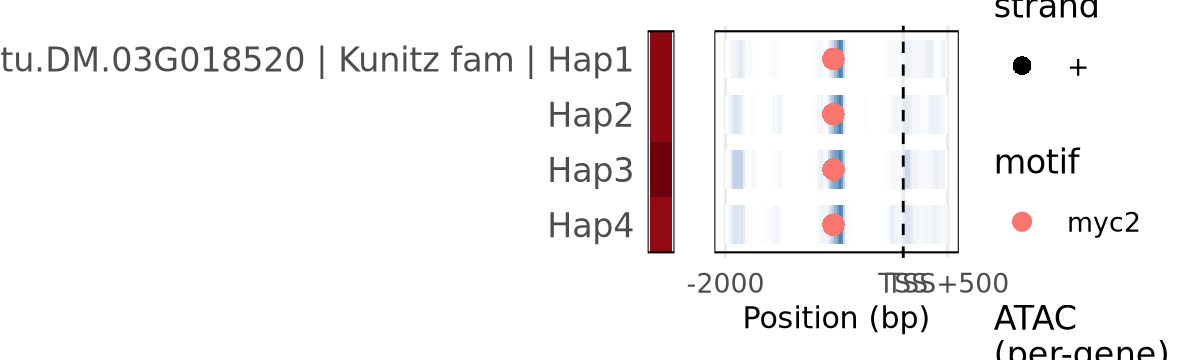

In [7]:
options(repr.plot.width = 10, repr.plot.height = 3)

# --- MYC2 PWM (JASPAR MA0566.1, rows A, C, G, T) ---
myc2_counts <- rbind(
  A = c(25, 9, 97, 0, 15, 1, 0, 5),
  C = c(10, 91, 0, 85, 0, 2, 0, 60),
  G = c(60, 0, 2, 0, 85, 0, 91, 10),
  T = c(5, 0, 1, 15, 0, 97, 9, 25)
)
storage.mode(myc2_counts) <- "integer"
kunitz_pwms <- list(myc2 = PWM(myc2_counts))

# this panel is restricted to a single gene of interest (independent of the full
# gene set plotted above); listed as a vector so more genes can be added back later
kunitz_genes_to_plot <- c("Soltu.DM.03G018520")
kunitz_wanted <- kunitz_genes_to_plot
# match on "<gene_id>." (with the trailing dot) so a gene id that happens to be a
# string-prefix of another (e.g. "Soltu.DM.03G023500" vs. "...G023500_1") can't
# accidentally swallow the other gene's sequences
kunitz_idx    <- unlist(lapply(kunitz_wanted, function(g) which(startsWith(names(promoter_seqs_all), paste0(g, ".")))))
kunitz_seqs   <- promoter_seqs_all[kunitz_idx]

kunitz_motifs <- do.call(rbind, Map(function(p, n) scan_pwm(p, kunitz_seqs, name = n),
                                     kunitz_pwms, names(kunitz_pwms)))

# gene order = the order of kunitz_genes_to_plot above
kunitz_id_order <- unlist(lapply(kunitz_wanted,
                                  function(g) names(kunitz_seqs)[startsWith(names(kunitz_seqs), paste0(g, "."))]))
kunitz_motifs$id <- factor(kunitz_motifs$id, levels = rev(kunitz_id_order))

kunitz_gene_of <- vapply(names(kunitz_seqs), function(x) {
  i <- which(startsWith(x, paste0(kunitz_wanted, "."))); if (length(i)) kunitz_wanted[i[1]] else NA_character_
}, character(1))

kunitz_ann   <- setNames(kunitz_annot_map$functional_annotation, kunitz_annot_map$gene_id_unitato)
kunitz_hap_of <- str_extract(names(kunitz_seqs), "Hap\\d+")
names(kunitz_hap_of) <- names(kunitz_seqs)

kunitz_plot_order <- rev(levels(kunitz_motifs$id))
kunitz_first_id   <- kunitz_plot_order[!duplicated(kunitz_gene_of[kunitz_plot_order])]

kunitz_id_labels <- ifelse(names(kunitz_seqs) %in% kunitz_first_id,
                     paste0(kunitz_gene_of, " | ", substr(kunitz_ann[kunitz_gene_of], 1, 10), " | ", kunitz_hap_of[names(kunitz_seqs)]),
                     kunitz_hap_of[names(kunitz_seqs)])
names(kunitz_id_labels) <- names(kunitz_seqs)

kunitz_regions <- promoter_regions_all[names(promoter_regions_all) %in% kunitz_id_order]
kunitz_atac    <- extract_bw_signal(ATAC_BIGWIG, kunitz_regions, bin = 25)
kunitz_atac    <- kunitz_atac %>%
  group_by(id) %>%
  mutate(signal_norm = (signal - min(signal)) / (max(signal) - min(signal))) %>%
  ungroup()
kunitz_atac$id <- factor(kunitz_atac$id, levels = rev(kunitz_id_order))

# per-(gene x haplotype) log2FC table matching the FASTA ids
kunitz_fc_long <- data.frame(
  id   = names(kunitz_seqs),
  gene = kunitz_gene_of[names(kunitz_seqs)],
  hap  = kunitz_hap_of[names(kunitz_seqs)],
  stringsAsFactors = FALSE
)
kunitz_fc_long$logFC <- mapply(function(g, h) {
  if (!is.na(g) && g %in% rownames(kunitz_mat_logfc) && h %in% colnames(kunitz_mat_logfc))
    kunitz_mat_logfc[g, h] else NA_real_
}, kunitz_fc_long$gene, kunitz_fc_long$hap)
kunitz_fc_long$logFC_capped <- pmin(pmax(kunitz_fc_long$logFC, -kunitz_cap), kunitz_cap)
kunitz_fc_long$id <- factor(kunitz_fc_long$id, levels = rev(kunitz_id_order))

# gene boundary boxes (group each gene's haplotype rows)
kunitz_box_df <- data.frame(id = levels(kunitz_fc_long$id),
                            ypos = seq_along(levels(kunitz_fc_long$id)),
                            stringsAsFactors = FALSE)
kunitz_box_df$gene <- kunitz_gene_of[kunitz_box_df$id]
kunitz_box_df <- kunitz_box_df %>%
  group_by(gene) %>%
  summarise(ymin = min(ypos) - 0.5, ymax = max(ypos) + 0.5, .groups = "drop")

kunitz_motifs <- collapse_overlapping_hits(kunitz_motifs)

# same sequential Reds palette and 0..kunitz_cap range as the Panel C heatmap above (same
# underlying log2FC values, so a color means the same thing in both); oob = squish clips
# values beyond the cap into the end color instead of dropping them to NA/blank, matching
# the heatmap's explicit pmin/pmax(0, kunitz_cap) clipping
p_kunitz_fc <- ggplot(kunitz_fc_long, aes(x = "0", y = id, fill = logFC_capped)) +
  geom_tile() +
  scale_fill_gradientn(colours = colorRampPalette(brewer.pal(9, "Reds"))(100),
                        limits = c(0, kunitz_cap), oob = scales::squish, name = "log2FC") +
  scale_y_discrete(labels = kunitz_id_labels) +
  geom_rect(data = kunitz_box_df,
            aes(xmin = -Inf, xmax = Inf - 0.5, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 18) +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
        axis.text.y = element_text(size = 20), panel.grid = element_blank(),
        legend.key.size = unit(1.2, "cm"))

p_kunitz_atac <- ggplot() +
  geom_tile(data = kunitz_atac, aes(x = pos, y = id, fill = signal_norm), width = 25, height = 0.7) +
  scale_fill_gradient(low = "white", high = "steelblue", name = "ATAC\n(per-gene)", transform = "pseudo_log") +
  geom_point(data = kunitz_motifs, aes(x = pos, y = id, color = motif, shape = strand), size = 6) +
  geom_vline(xintercept = 2000, linetype = "dashed", color = "black", linewidth = 0.8) +
  geom_rect(data = kunitz_box_df,
            aes(xmin = -Inf, xmax = Inf, ymin = ymin, ymax = ymax),
            inherit.aes = FALSE, fill = NA, color = "black", linewidth = 0.6) +
  scale_y_discrete(labels = kunitz_id_labels) +
  scale_x_continuous(breaks = c(0, 2000, 2500), labels = c("-2000", "TSS", "TSS+500")) +
  labs(x = "Position (bp)", y = NULL) +
  theme_minimal(base_size = 20) +
  theme(axis.text.y = element_blank(), axis.title.x = element_text(size = 18),
        panel.grid.minor = element_blank(), panel.grid.major.y = element_blank(),
        legend.key.size = unit(1.2, "cm")) +
  guides(color = guide_legend(override.aes = list(size = 5)),
         shape = guide_legend(override.aes = list(size = 5)))

p_kunitz <- p_kunitz_fc + p_kunitz_atac + plot_layout(widths = c(0.33, 3), guides = "collect")
p_kunitz
ggsave(file.path(OUT_DIR, "Fig4C_kunitz_promoter_motif_atac.svg"), p_kunitz, width = 14, height = 10, units = "in")
